## DECOM: INTELIGENCIA COMPUTACIONAL, Prof. Rogério; Autor: Marco Túlio S. da Mata; CEFET-MG

# Otimização por Colônia de Formigas (Ant Colony Optimization) aplicada ao Problema do Caixeiro Viajante

Algoritmo de **Otimização por Colônia de Formigas (ACO)** para
resolver o **Problema do Caixeiro Viajante (TSP)**: dado um conjunto de cidades com coordenadas
(X, Y), encontrar a rota de menor distância total que visita cada cidade exatamente uma vez e
retorna à cidade de origem.

## 1. Fundamentação teórica

O algoritmo ACO é inspirado no comportamento de formigas reais ao buscar comida: elas depositam
**feromônio** no caminho percorrido, e caminhos mais curtos acabam acumulando mais feromônio (pois
são percorridos mais rapidamente e com mais frequência), o que atrai mais formigas para esses
caminhos ao longo do tempo — um processo de **retroalimentação positiva**.

No contexto do TSP, cada formiga constrói uma rota completa escolhendo, a cada passo, a próxima
cidade a visitar com base em uma regra probabilística que combina dois fatores:

- **Feromônio (τ)**: quanto mais feromônio existe na aresta entre duas cidades, mais atrativa ela é.
- **Visibilidade/heurística (η)**: o inverso da distância entre as cidades (1/distância) — cidades
  mais próximas são naturalmente mais atrativas.

A probabilidade de uma formiga na cidade *i* escolher a cidade *j* como próximo destino é dada por:

$$
p_{ij} = \frac{(\tau_{ij})^{\alpha} \cdot (\eta_{ij})^{\beta}}{\sum_{k \in \text{permitidas}} (\tau_{ik})^{\alpha} \cdot (\eta_{ik})^{\beta}}
$$

Onde:
- **α (alpha)** controla a importância do feromônio.
- **β (beta)** controla a importância da distância/heurística.

Ao final de cada iteração (após todas as formigas construírem suas rotas):

1. O feromônio de todas as arestas **evapora** a uma taxa ρ (rho): $\tau_{ij} \leftarrow (1 - \rho)\, \tau_{ij}$
2. Cada formiga **deposita** feromônio proporcional à qualidade da sua rota: $\Delta\tau_{ij} = Q / L$,
   onde *L* é o comprimento total da rota e *Q* é uma constante.

Repetindo este processo por várias iterações, o algoritmo converge para rotas cada vez mais curtas.

## 2. Carregamento dos dados

Vamos carregar o arquivo `cidades.csv` (formato `Cidade;X;Y`) e calcular a matriz de distâncias
euclidianas entre todas as cidades. As funções usadas aqui vêm do módulo `aco_tsp.py`.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from aco_tsp import (
    carregar_cidades,
    matriz_distancias,
    AntColonyTSP,
    plotar_rota,
    plotar_convergencia,
    rota_para_nomes,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 100


In [3]:
CAMINHO_CSV = "cidades.csv"  # ajuste o caminho conforme necessário

df_cidades = carregar_cidades(CAMINHO_CSV)
df_cidades


,Cidade,X,Y
0,Belo Horizonte,63.94,2.50
1,Sao Paulo,27.50,22.32
2,Rio de Janeiro,73.65,67.67
3,Salvador,89.22,8.69
4,Fortaleza,42.19,2.98
5,Brasilia,21.86,50.54
6,Curitiba,2.65,19.88
7,Manaus,64.99,54.49
8,Recife,22.04,58.93
9,Porto Alegre,80.94,0.65


In [4]:
distancias = matriz_distancias(df_cidades)
print(f"Número de cidades: {distancias.shape[0]}")
print("Matriz de distâncias (primeiras linhas/colunas):")
pd.DataFrame(distancias, index=df_cidades["Cidade"], columns=df_cidades["Cidade"]).round(2).iloc[:5, :5]


Número de cidades: 20
Matriz de distâncias (primeiras linhas/colunas):


Cidade,Belo Horizonte,Sao Paulo,Rio de Janeiro,Salvador,Fortaleza
Cidade,,,,,
Belo Horizonte,0.00,41.48,65.89,26.03,21.76
Sao Paulo,41.48,0.00,64.70,63.21,24.29
Rio de Janeiro,65.89,64.70,0.00,61.00,71.93
Salvador,26.03,63.21,61.00,0.00,47.38
Fortaleza,21.76,24.29,71.93,47.38,0.00


### Visualizando as cidades no plano

Antes de rodar o algoritmo, é útil visualizar a distribuição espacial das cidades.

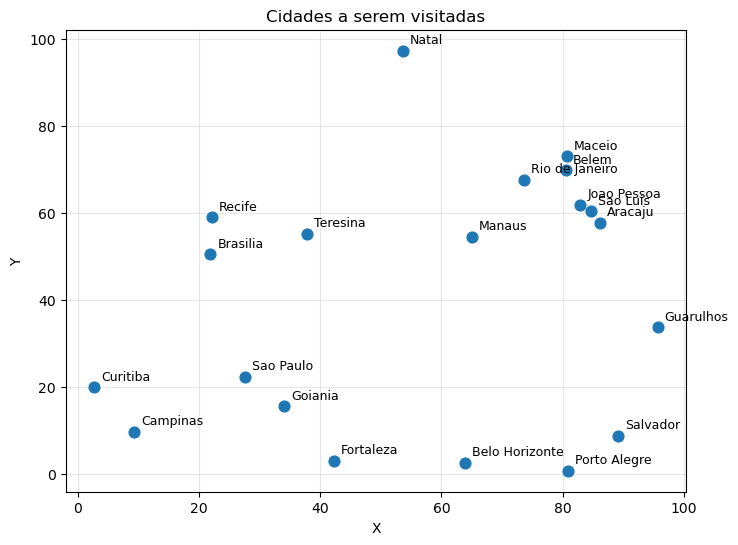

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df_cidades["X"], df_cidades["Y"], color="tab:blue", s=60, zorder=3)
for _, row in df_cidades.iterrows():
    ax.annotate(row["Cidade"], (row["X"], row["Y"]), textcoords="offset points", xytext=(5, 5), fontsize=9)
ax.set_title("Cidades a serem visitadas")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.grid(alpha=0.3)
plt.show()


## 3. Configuração e execução do algoritmo ACO

Os principais hiperparâmetros do algoritmo são:

| Parâmetro | Descrição | Valor usado |
|---|---|---|
| `n_formigas` | Número de formigas por iteração | 30 |
| `n_iteracoes` | Número de iterações | 150 |
| `alpha` | Peso do feromônio | 1.0 |
| `beta` | Peso da heurística (1/distância) | 3.0 |
| `taxa_evaporacao` | Taxa de evaporação do feromônio | 0.5 |
| `Q` | Constante de depósito de feromônio | 100.0 |

Esses valores são um bom ponto de partida, mas podem (e devem) ser ajustados conforme o problema.

In [6]:
aco = AntColonyTSP(
    distancias=distancias,
    n_formigas=30,
    n_iteracoes=150,
    alpha=1.0,
    beta=3.0,
    taxa_evaporacao=0.5,
    Q=100.0,
    semente=42,  # para resultados reprodutíveis
)

historico = aco.executar()

print(f"Melhor distância encontrada: {historico.melhor_distancia_global:.2f}")
print("Melhor rota (índices):", historico.melhor_rota_global)
print("Melhor rota (nomes):", rota_para_nomes(df_cidades, historico.melhor_rota_global))


Melhor distância encontrada: 352.33
Melhor rota (índices): [16, 7, 2, 15, 10, 18, 14, 19, 12, 3, 9, 0, 4, 11, 1, 13, 6, 5, 8, 17]
Melhor rota (nomes): ['Natal', 'Manaus', 'Rio de Janeiro', 'Maceio', 'Belem', 'Joao Pessoa', 'Sao Luis', 'Aracaju', 'Guarulhos', 'Salvador', 'Porto Alegre', 'Belo Horizonte', 'Fortaleza', 'Goiania', 'Sao Paulo', 'Campinas', 'Curitiba', 'Brasilia', 'Recife', 'Teresina']


## 4. Visualização dos resultados

### 4.1 Melhor rota encontrada

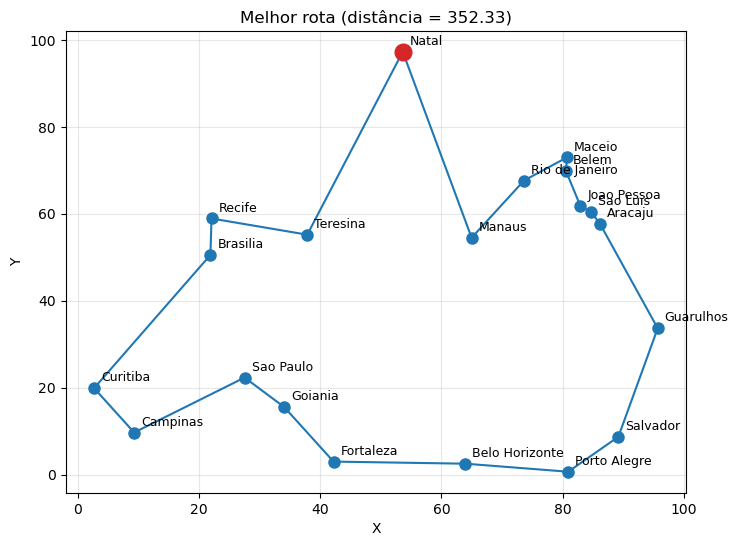

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
plotar_rota(df_cidades, historico.melhor_rota_global, ax=ax,
            titulo=f"Melhor rota (distância = {historico.melhor_distancia_global:.2f})")
plt.show()


### 4.2 Curva de convergência

O gráfico abaixo mostra como a melhor distância e a distância média evoluem a cada iteração,
evidenciando a convergência do algoritmo.

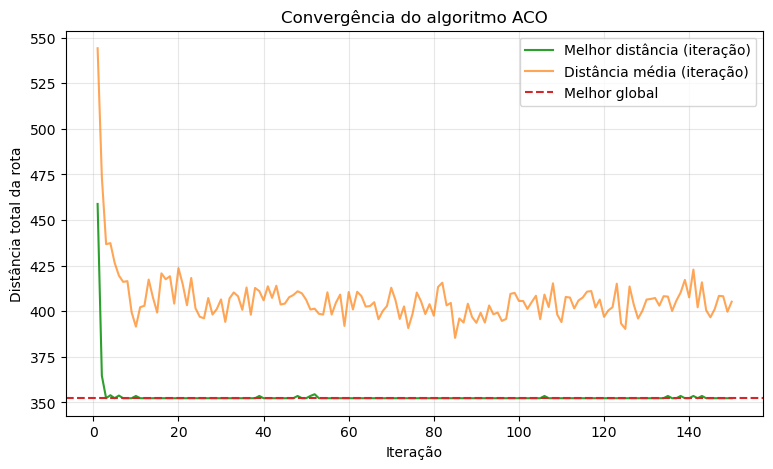

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
plotar_convergencia(historico, ax=ax)
plt.show()


## 5. Experimentos: efeito dos parâmetros

Nesta seção comparamos a influência de diferentes valores de **alpha**, **beta** e
**taxa de evaporação** na qualidade da solução e na velocidade de convergência.

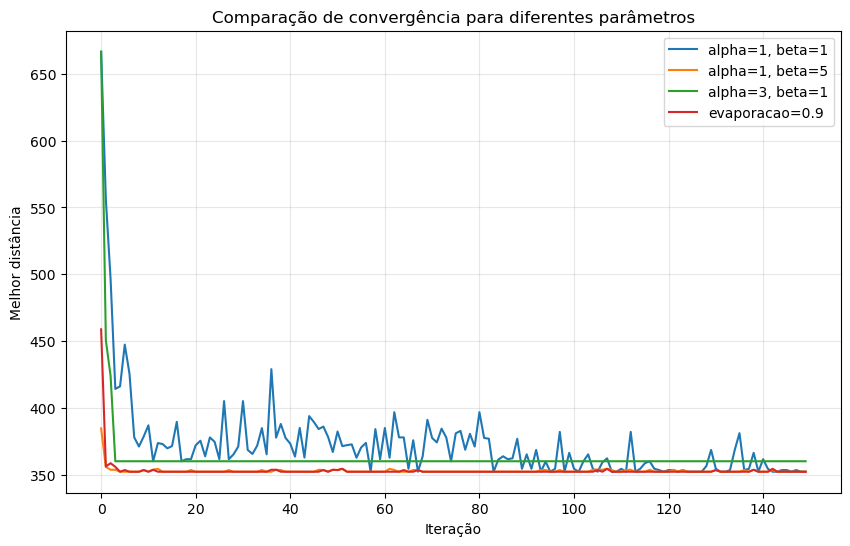

alpha=1, beta=1      -> melhor distância: 352.33
alpha=1, beta=5      -> melhor distância: 352.33
alpha=3, beta=1      -> melhor distância: 360.16
evaporacao=0.9       -> melhor distância: 352.33


In [9]:
configuracoes = [
    {"alpha": 1.0, "beta": 1.0, "taxa_evaporacao": 0.5, "label": "alpha=1, beta=1"},
    {"alpha": 1.0, "beta": 5.0, "taxa_evaporacao": 0.5, "label": "alpha=1, beta=5"},
    {"alpha": 3.0, "beta": 1.0, "taxa_evaporacao": 0.5, "label": "alpha=3, beta=1"},
    {"alpha": 1.0, "beta": 3.0, "taxa_evaporacao": 0.9, "label": "evaporacao=0.9"},
]

resultados = {}

for cfg in configuracoes:
    aco_teste = AntColonyTSP(
        distancias=distancias,
        n_formigas=30,
        n_iteracoes=150,
        alpha=cfg["alpha"],
        beta=cfg["beta"],
        taxa_evaporacao=cfg["taxa_evaporacao"],
        Q=100.0,
        semente=42,
    )
    hist_teste = aco_teste.executar()
    resultados[cfg["label"]] = hist_teste

fig, ax = plt.subplots(figsize=(10, 6))
for label, hist in resultados.items():
    ax.plot(hist.melhor_distancia_por_iteracao, label=label)
ax.set_title("Comparação de convergência para diferentes parâmetros")
ax.set_xlabel("Iteração")
ax.set_ylabel("Melhor distância")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

for label, hist in resultados.items():
    print(f"{label:20s} -> melhor distância: {hist.melhor_distancia_global:.2f}")


## 6. Conclusão

O algoritmo ACO implementado em `aco_tsp.py` resolve o Problema do Caixeiro Viajante de forma
heurística, encontrando rotas de boa qualidade em um número relativamente pequeno de iterações.

Os principais pontos de atenção ao aplicar o algoritmo em outros conjuntos de cidades são:

- **Escala do problema**: para um número muito grande de cidades, pode ser necessário aumentar o
  número de formigas/iterações ou usar variantes mais eficientes (ex.: *Ant Colony System*,
  *MAX-MIN Ant System*).
- **Ajuste de parâmetros**: `alpha`, `beta` e a taxa de evaporação afetam fortemente o equilíbrio
  entre exploração (diversificação) e exploração (intensificação) do espaço de busca.
- **Reprodutibilidade**: lembre do parâmetro `seed` para obter resultados reprodutíveis durante
  testes e comparações.